# Example 0: getting started

This notebook checks that DMS is installed and runs a first, very small model (less than a minute).

**Before opening it** (once; details in the README, *Prerequisites* and *Installation*):

1. Install a Fortran compiler with OpenMP (gfortran) and the Python packages:
   `python3 -m pip install -r requirements.txt`
2. Build DMS in a terminal, in the repository folder:
   `make` (the program `bin/dms`) and `make python` (the Python extension)
3. Start Jupyter in the repository folder: `jupyter lab`, and open
   `examples/0_getting_started.ipynb` in the file browser on the left.

Run the cells one after the other with **Shift + Enter**.

In [1]:
# Setup: this notebook lives in the examples/ folder of the repository
import os, sys
REPO = os.environ.get("DMS_REPO") or os.path.abspath("..")
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__, "from", os.path.relpath(os.path.dirname(dms.__file__), REPO))

DMS 2.0.0 from python/dms


## 1. Check the installation

The check runs with the Python of this notebook. The Python extension of DMS works only with the
Python it was built with: if the check says that it was built for another Python, run the
`make python PYTHON=...` command that it prints, then restart the kernel (*Kernel → Restart*).

In [ ]:
import subprocess
check = subprocess.run([sys.executable, os.path.join(REPO, "tools", "check_setup.py")],
                       capture_output=True, text=True)
print(check.stdout)

## 2. The smallest model: an SED

A ring of dust between 50 and 100 au around a Sun-like star at 20 pc. `mode = "sed"` computes the
spectral energy distribution directly, without images. Names and units are those of the input
files (au, degrees, M☉, micron); everything that is not given keeps its default.

In [3]:
model = dms.Model(
    run={"mode": "sed"},
    star={"teff": 5800, "radius": 1.0, "mass": 1.0, "distance": 20},     # K, R_sun, M_sun, pc
    disk={"r_in": 50, "r_out": 100, "dust_mass": 1e-8},                    # au, M_sun
    dust={"n_components": 1, "optical_data": "astrosilicate_draine03_862",
          "bulk_density": 3.5},                                           # g/cm^3
    wavelengths={"lambda": [10, 24, 70, 160, 870]},                       # micron
)
res = model.run()

print(f"fractional luminosity f_d = {res.f_d:.2e}")
for lam, flux in zip(res.wavelength, res.sed["thermal"]):
    print(f"{lam:6.0f} micron   {1e3 * flux:9.3f} mJy")

fractional luminosity f_d = 8.09e-05
    10 micron       0.001 mJy
    24 micron      10.034 mJy
    70 micron      88.726 mJy
   160 micron      63.899 mJy
   870 micron       1.842 mJy


## 3. A first image

The same disk seen at 60° inclination, as an image at 70 µm. `model.copy().update(...)` changes
some parameters of a copy and keeps the original model as it is.

101 x 101 pixels of 1.98 au


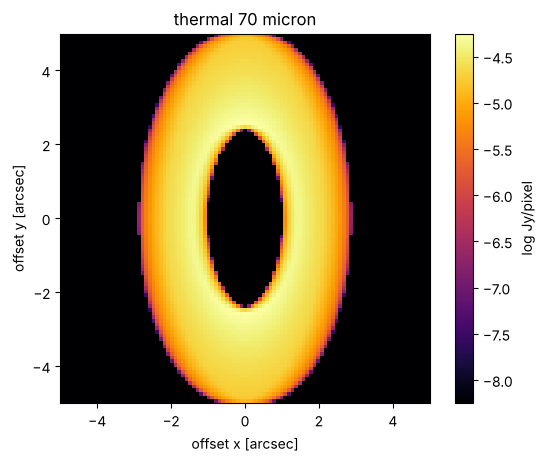

In [4]:
img = model.copy().update(run={"mode": "image"}, wavelengths={"lambda": [70]},
                          image={"n_pixels": 101}, disk={"inclination": 60}).run()
print(f"{img.image('thermal').shape[1]} x {img.image('thermal').shape[2]} pixels of {img.pixel_au:.2f} au")
dms.plot.image(img, "thermal")
plt.show()

## 4. What next

DMS works. Continue with

* `1_first_model.ipynb`: SED and images of a ring, and how to change a model,
* `2_two_belts_observed.ipynb`: two belts of icy grains, observed with a PSF and a coronagraph mask,
* `3_parameter_study.ipynb`: many models in parallel.

From a terminal, `bin/dms examples/debris_ring.nml` runs an input file (results in `results/`), and
`make test` runs the test suite (about a minute).

## Troubleshooting

| message | what to do |
|---|---|
| `ImportError: the compiled DMS extension is missing` | `make python` was not run, or was run with another Python than this notebook. Run the `make python PYTHON=...` command printed by the check above and restart the kernel. |
| `Cannot use distutils backend with Python>=3.12`, then the build stops | `python3 -m pip install meson ninja`, then `make python` again. |
| `gfortran: command not found` (or `No such file or directory` for gfortran) | Install the compiler: macOS `brew install gcc`, Debian/Ubuntu `sudo apt install gfortran`. |
| `module 'numpy' has no attribute ...` | NumPy is too old for DMS (needs ≥ 1.22): `python3 -m pip install --upgrade numpy`. |
| `dms.DMSError: ...` | The message names the input that is wrong (see `docs/input_reference.md`). The Python session keeps running. |
| No output, or you want to see what the Fortran code prints | `model.run(quiet=False)`: the screen output of the Fortran code appears in the terminal in which Jupyter was started, not in the notebook. |